# Week 1 실습: 동전 맞히기 예제로 보는 사전분포와 사후분포

100번 중 60번 맞힌 상황에서 균등 사전분포 $Unif(0,1)$을 두고 사후분포를 구한다. 개념 정리는 [notes.md](./notes.md) 참고.

In [1]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)
plt.rcParams["figure.figsize"] = (7, 4)

## 1. 사후분포: Beta(x+1, n-x+1)

In [2]:
n, x = 100, 60
a_post, b_post = x + 1, n - x + 1
posterior = stats.beta(a_post, b_post)

print(f"posterior: Beta({a_post}, {b_post})")
print(f"MLE                 : {x/n:.3f}")
print(f"posterior mean      : {posterior.mean():.3f}")
print(f"MAP                 : {(a_post-1)/(a_post+b_post-2):.3f}  (균등 사전분포라 MLE와 같음)")
print(f"posterior sd        : {posterior.std():.4f}")
print(f"P(theta > 0.5 | x)  : {posterior.sf(0.5):.3f}")

posterior: Beta(61, 41)
MLE                 : 0.600
posterior mean      : 0.598
MAP                 : 0.600  (균등 사전분포라 MLE와 같음)
posterior sd        : 0.0483
P(theta > 0.5 | x)  : 0.977


## 2. 사전분포 vs 사후분포

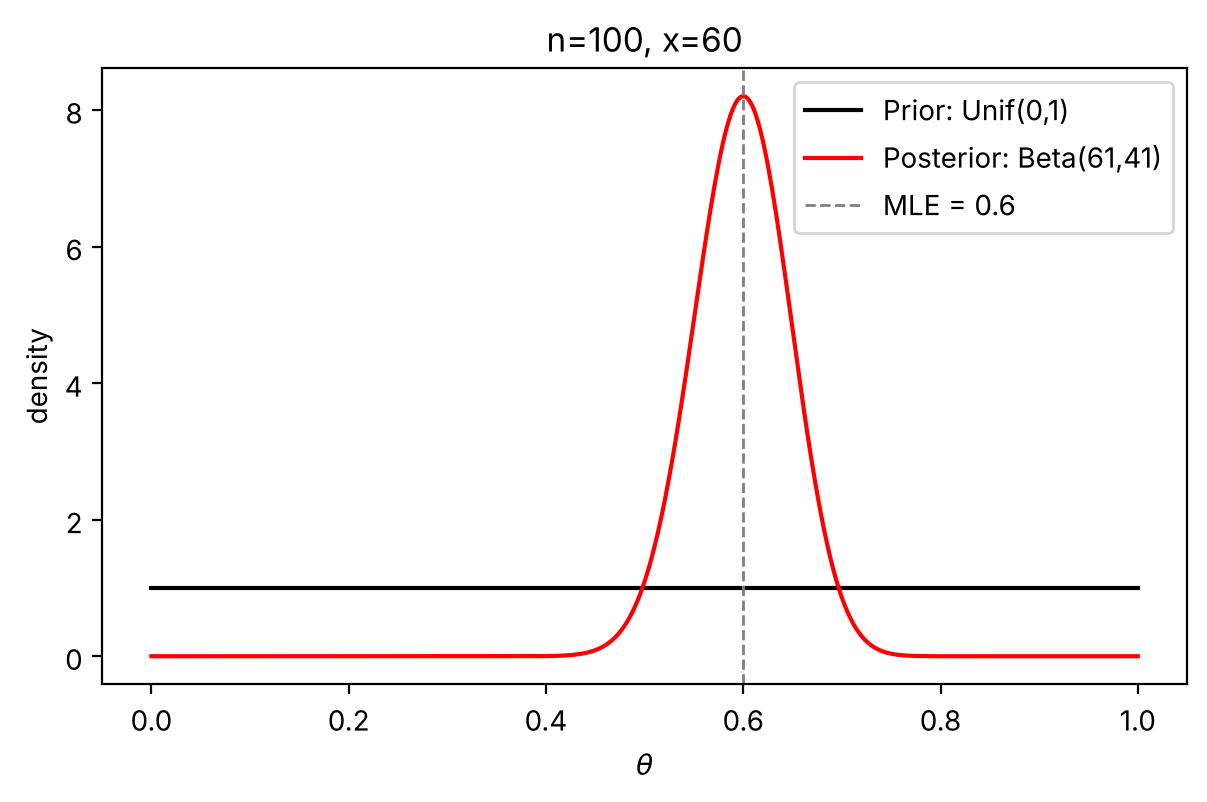

In [3]:
grid = np.linspace(0, 1, 500)
plt.plot(grid, stats.uniform.pdf(grid), "k", label="Prior: Unif(0,1)")
plt.plot(grid, posterior.pdf(grid), "r", label=f"Posterior: Beta({a_post},{b_post})")
plt.axvline(x/n, ls="--", c="gray", lw=1, label="MLE = 0.6")
plt.xlabel(r"$\theta$"); plt.ylabel("density"); plt.legend(); plt.title("n=100, x=60")
plt.show()

## 3. 95% 신용구간

θ가 이 구간에 있을 **사후확률**이 0.95라고 그대로 해석할 수 있다.

In [4]:
lo, hi = posterior.ppf([0.025, 0.975])
print(f"95% equal-tailed credible interval: ({lo:.3f}, {hi:.3f})")

95% equal-tailed credible interval: (0.502, 0.691)


## 4. 사전분포에 따라 사후분포가 얼마나 달라질까?

같은 데이터(60/100)에 서로 다른 베타 사전분포를 줘 봤다. 데이터가 100개라 웬만한 사전분포는 금방 압도되지만, 사전 표본 크기($a+b$)가 크면 사후분포가 끌려간다.

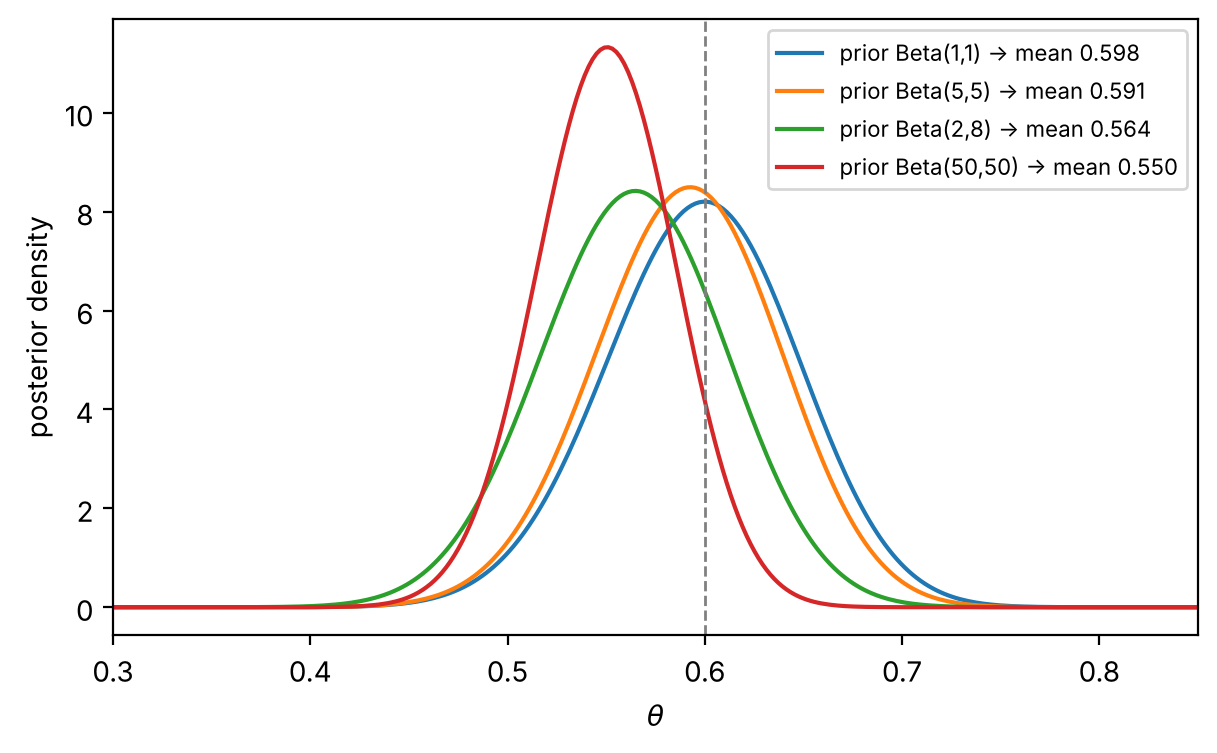

In [5]:
priors = {"Beta(1,1)": (1, 1), "Beta(5,5)": (5, 5), "Beta(2,8)": (2, 8), "Beta(50,50)": (50, 50)}
for name, (a, b) in priors.items():
    post = stats.beta(a + x, b + n - x)
    plt.plot(grid, post.pdf(grid), label=f"prior {name} -> mean {post.mean():.3f}")
plt.axvline(x/n, ls="--", c="gray", lw=1)
plt.xlim(0.3, 0.85); plt.xlabel(r"$\theta$"); plt.ylabel("posterior density"); plt.legend(fontsize=8)
plt.show()

## 5. 데이터가 쌓일수록 사후분포가 좁아지는 모습

θ=0.6인 동전 맞히기를 시뮬레이션하면서, 사후분포를 순차적으로 업데이트했다. 이번 사후분포가 다음 단계의 사전분포가 된다.

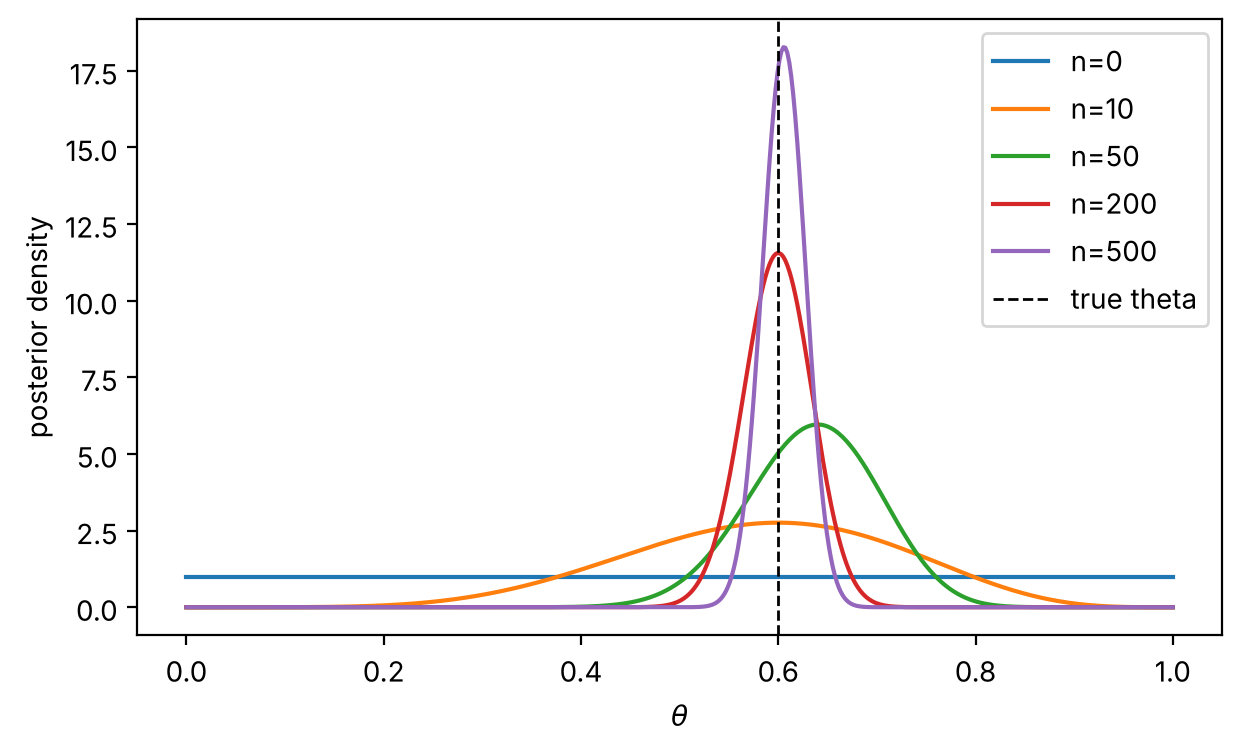

In [6]:
true_theta = 0.6
data = rng.binomial(1, true_theta, size=500)
a, b = 1, 1
checkpoints = [0, 10, 50, 200, 500]
prev = 0
for n_seen in checkpoints:
    batch = data[prev:n_seen]
    a, b = a + batch.sum(), b + len(batch) - batch.sum()   # 이전 사후분포 -> 새 사전분포
    prev = n_seen
    plt.plot(grid, stats.beta(a, b).pdf(grid), label=f"n={n_seen}")
plt.axvline(true_theta, ls="--", c="k", lw=1, label="true theta")
plt.xlabel(r"$\theta$"); plt.ylabel("posterior density"); plt.legend()
plt.show()